[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Naviden/Introduction-to-XAI/blob/main/Tools/Evaluation_examples/Regression_Benchmark.ipynb)

[Colab setup: dependencies and repository files](https://github.com/Naviden/Introduction-to-XAI/blob/main/docs/REPRODUCIBILITY.md#google-colab)

**Validated reading copy.** Run the [source notebook](../../../../Tools/Evaluation_examples/Regression_Benchmark.ipynb) in its original directory. This snapshot includes checked outputs; source SHA-256: `228713283d21bd5abc50ef5a54a99a4d4653686d84794b9e42cef3eed43deaa1`. Timings describe this recorded environment, not a performance guarantee.

# A small, auditable regression benchmark for explanations

**Question:** how do explanation diagnostics and resource costs behave across different regression problems, fitted models and prespecified cases?

This offline protocol uses two synthetic mechanisms and a fixed six-feature subset of the bundled diabetes regression dataset. Each setting has **five predetermined repeats** and **eight presampled held-out cases**. SHAP Exact and LIME explain the same fitted forest in each run. Exact finite-background Shapley enumeration supplies a numerical reference for the specified attribution game; random feature rankings supply a control for a separate removal test.

Install `requirements-tabular.txt`. CPU only; no downloads or neural libraries. Run from this folder. The helper `regression_helpers.py` defines the exact game and measurement boundaries. Results, raw case-level records, resource measurements and figures are written under the ignored repository `validation/regression-benchmark/` directory.

This is a protocol demonstration, **not a leaderboard**. Predictive performance, additive correctness, sensitivity to removal, and computational cost answer distinct questions. Different datasets have different target units; we never average their raw errors or removal scores together.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from lime.lime_tabular import LimeTabularExplainer
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from regression_helpers import exact_background_shapley, measured_explanation, removal_response

ROOT = Path.cwd().resolve().parents[1]
assert (ROOT / 'README.md').exists(), 'Run from Tools/Evaluation_examples/.'
OUTPUT = ROOT / 'validation' / 'regression-benchmark'
OUTPUT.mkdir(parents=True, exist_ok=True)
SEEDS = [11, 22, 33, 44, 55]
SETTINGS = dict(synthetic_rows=900, test_fraction=.25, cases_per_run=8, background_rows=24,
                forest_trees=64, forest_depth=6, minimum_leaf=4,
                lime_samples=800, random_rankings=5, empirical_donors=8)
SCENARIOS = ['Synthetic additive', 'Synthetic nonlinear proxy', 'Diabetes (six fixed features)']
COLORS = {'SHAP Exact':'#3465a4', 'LIME':'#b04b68', 'Random ranking':'#777777', 'Exact Shapley reference':'#318c72'}
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})

def dataset_for(scenario, seed):
    rng = np.random.default_rng(2000+seed)
    if scenario.startswith('Synthetic'):
        X = rng.normal(size=(SETTINGS['synthetic_rows'], 6))
        if scenario == 'Synthetic additive':
            oracle = lambda rows: 2*rows[:,0] - 1.5*rows[:,1] + .75*rows[:,2]
        else:
            X[:,1] = .97*X[:,0] + np.sqrt(1-.97**2)*X[:,1]
            oracle = lambda rows: 2*np.sin(rows[:,0]) + rows[:,2]**2 - 1 + .8*rows[:,2]*rows[:,3]
        y = oracle(X) + rng.normal(0, .6, len(X))
        return X, y, [f'x{i}' for i in range(6)], oracle, 'arbitrary response units'
    data = load_diabetes(as_frame=True)
    names = ['bmi', 'bp', 's1', 's2', 's5', 's6']  # Fixed before any benchmark results.
    return data.data[names].to_numpy(), data.target.to_numpy(), names, None, 'dataset disease-progression score'

def make_operation(method, model, cases, training, background, names, seed):
    def operation():
        if method == 'SHAP Exact':
            explainer = shap.Explainer(model.predict, shap.maskers.Independent(background, max_samples=len(background)),
                                       algorithm='exact')
            result = explainer(cases)
            return dict(values=result.values, baseline=result.base_values, prediction=model.predict(cases))
        if method == 'Exact Shapley reference':
            values, baseline, predicted = exact_background_shapley(model.predict, cases, background)
            return dict(values=values, baseline=baseline, prediction=predicted)
        explainer = LimeTabularExplainer(training, feature_names=names, mode='regression',
                                        discretize_continuous=False, random_state=5000+seed)
        values, fits, local_predictions = [], [], []
        for row in cases:
            result = explainer.explain_instance(row, model.predict, num_features=len(names),
                                                 num_samples=SETTINGS['lime_samples'])
            weights = np.zeros(len(names))
            # In LIME regression, map key 1 contains coefficients for the numeric response.
            for feature, weight in result.as_map()[1]:
                weights[feature] = weight
            values.append(weights)
            fits.append(result.score)
            local_predictions.append(float(np.asarray(result.local_pred).ravel()[0]))
        return dict(values=np.asarray(values), local_r2=np.asarray(fits),
                    local_prediction=np.asarray(local_predictions), prediction=model.predict(cases))
    return operation

/Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Predetermine the data, splits, cases and model budgets

The additive generating function is $2x_0-1.5x_1+0.75x_2$. The nonlinear function is $2\sin(x_0)+x_2^2-1+0.8x_2x_3$, with $x_1$ a correlation-0.97 proxy for $x_0$. Both receive Gaussian target noise with SD 0.6. A proxy can be useful to a fitted predictor even when it has no direct term in the generating function.

For synthetic repeats, generate new datasets from seeds declared above. For diabetes, reuse the bundled dataset and change the split; these repeated holdouts overlap. A random forest with identical fixed capacity is trained on each training partition. Eight test positions and 24 training-background positions are selected by seeded sampling without using outcomes, predictions or explanation results. Hyperparameters are not tuned against the test sets.

The five-run SD measures dispersion under this protocol. It is **not a standard error or confidence interval**: synthetic repeats change data, split and model; the real-data splits overlap. Individual cases, random rankings and replacement donors are not counted as independent training runs.

## 2. Define what is measured

- **Predictive quality:** held-out MAE, RMSE and $R^2$ in the target's units. Where the generating function is known, separately measure model error against that noiseless function.
- **Numerical attribution reference:** enumerate all $2^6$ coalitions for each case and the 24-row background. It computes the marginal replacement game $v(S)=E_B[f(x_S,B_{\bar S})]$. SHAP's model-agnostic ExactExplainer should agree numerically with this independently enumerated game for the fitted forest. This check is not proof that the game is the right explanation for a human task.
- **LIME approximation:** report the local surrogate's weighted neighborhood $R^2$ and prediction gap. LIME's standardized-feature coefficients are not the same quantity as Shapley contributions, so we do not score them as numerical errors against Shapley values.
- **Removal response:** rank absolute attributions/weights, then replace increasingly many features with either a training-mean vector or jointly sampled donor rows. Measure absolute model-output change and integrate over the fraction removed. Higher area means earlier removal changed this model more under that replacement; it does not establish universal superiority. Missing-feature replacements can violate cross-feature dependence.

Every method shares the model, cases and evaluation donors in its run. Random ranking repetitions are averaged within a run before comparing the five run means.

## 3. Measure cost without mixing unlike quantities

For each explainer we measure one full construction-and-explanation call:

1. **Wall time**, without allocation tracing. It includes constructing the explainer and any model prediction calls used in its returned diagnostics, excludes model fitting, and is not warmed up deliberately. A per-case value amortizes setup; it is not request latency.
2. **Public `predict` calls and rows**, counted on the fitted model during that timed call. All three procedures call this prediction interface. Counts measure observed batch invocations and evaluated rows, not the full arithmetic workload inside the forest or explainer. Different batch sizes change costs, so call counts alone are not a speed ranking.
3. **Peak traced allocation bytes** in a separate identical rerun using Python's `tracemalloc`. This measures allocations traced during the operation, excludes the already fitted model, and can miss native buffers. It is **not total process RSS or a total-memory requirement**. Tracing overhead is excluded from the wall-time measurement.

The two executions use freshly constructed explainers and the same seeds. The memory rerun follows the timing run, so process-level caches or just-in-time compilation may already be warm; these are not isolated cold-process measurements. Raw records retain the measured values, settings and machine/software details. Timings and memory measurements are environment-dependent observations, not fixed expected outputs.

In [2]:
runs, manifests = {}, []
predictive_rows, resource_rows, diagnostic_rows, attribution_rows = [], [], [], []
for scenario in SCENARIOS:
    for seed in SEEDS:
        X, y, names, oracle, units = dataset_for(scenario, seed)
        train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=SETTINGS['test_fraction'], random_state=seed)
        training, test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
        model = RandomForestRegressor(n_estimators=SETTINGS['forest_trees'], max_depth=SETTINGS['forest_depth'],
                                       min_samples_leaf=SETTINGS['minimum_leaf'], random_state=seed, n_jobs=1)
        model.fit(training, y_train)
        predicted = model.predict(test)
        case_rng, background_rng = np.random.default_rng(4000+seed), np.random.default_rng(3000+seed)
        case_positions = case_rng.choice(len(test), SETTINGS['cases_per_run'], replace=False)
        background_positions = background_rng.choice(len(training), SETTINGS['background_rows'], replace=False)
        cases, background = test[case_positions], training[background_positions]
        predictive_rows.append(dict(scenario=scenario, seed=seed, target_units=units,
                                    test_mae=mean_absolute_error(y_test, predicted),
                                    test_rmse=np.sqrt(mean_squared_error(y_test, predicted)),
                                    test_r2=r2_score(y_test, predicted),
                                    model_mae_to_noiseless_function=mean_absolute_error(oracle(test), predicted) if oracle else np.nan))
        results = {}
        for method in ['SHAP Exact','LIME','Exact Shapley reference']:
            results[method], resource = measured_explanation(
                model, make_operation(method, model, cases, training, background, names, seed))
            resource_rows.append(dict(scenario=scenario, seed=seed, method=method, cases=len(cases),
                                      seconds_per_case=resource['seconds']/len(cases), **resource))
        tree, exact, lime = results['SHAP Exact'], results['Exact Shapley reference'], results['LIME']
        np.testing.assert_allclose(tree['values'], exact['values'], atol=1e-5)
        np.testing.assert_allclose(exact['baseline']+exact['values'].sum(axis=1), exact['prediction'], atol=1e-10)
        np.testing.assert_allclose(tree['baseline']+tree['values'].sum(axis=1), tree['prediction'], atol=1e-5)
        oracle_values = exact_background_shapley(oracle, cases, background)[0] if oracle else None
        for case in range(len(cases)):
            diagnostic_rows.append(dict(scenario=scenario, seed=seed, case=case, dataset_row=int(test_idx[case_positions[case]]),
                                         observed_y=float(y_test[case_positions[case]]), model_prediction=float(tree['prediction'][case]),
                                         shap_exact_max_abs_difference=float(np.max(np.abs(tree['values'][case]-exact['values'][case]))),
                                         lime_local_r2=float(lime['local_r2'][case]),
                                         lime_local_prediction_gap=float(abs(lime['local_prediction'][case]-lime['prediction'][case]))))
            for j, feature in enumerate(names):
                attribution_rows.append(dict(scenario=scenario, seed=seed, case=case, feature=feature,
                                              fitted_model_shap=float(exact['values'][case,j]),
                                              generating_function_shap=float(oracle_values[case,j]) if oracle else np.nan,
                                              lime_standardized_feature_weight=float(lime['values'][case,j])))
        run_id = f'{scenario}:{seed}'
        runs[run_id] = dict(scenario=scenario, seed=seed, model=model, training=training, test=test,
                            cases=cases, results=results, target_training_sd=float(np.std(y_train,ddof=1)))
        manifests.append(dict(run_id=run_id, data_seed=2000+seed if oracle else None,
                              data_sha256=hashlib.sha256(np.ascontiguousarray(X).tobytes()).hexdigest(),
                              targets_sha256=hashlib.sha256(np.ascontiguousarray(y).tobytes()).hexdigest(),
                              features=names, target_units=units, train_indices=train_idx.tolist(), test_indices=test_idx.tolist(),
                              explained_dataset_indices=test_idx[case_positions].tolist(),
                              background_dataset_indices=train_idx[background_positions].tolist(),
                              model_parameters=model.get_params(), case_seed=4000+seed, background_seed=3000+seed,
                              lime_seed=5000+seed, target_training_sd=float(np.std(y_train,ddof=1))))

predictive = pd.DataFrame(predictive_rows)
resources = pd.DataFrame(resource_rows)
diagnostics = pd.DataFrame(diagnostic_rows)
attributions = pd.DataFrame(attribution_rows)
display(predictive.groupby('scenario')[['test_mae','test_rmse','test_r2','model_mae_to_noiseless_function']].agg(['mean','std']).round(3))
display(diagnostics.groupby('scenario')[['shap_exact_max_abs_difference','lime_local_r2','lime_local_prediction_gap']].agg(['mean','min','max']).round(6))
print('All SHAP Exact values matched the enumerated fitted-model game within the stated tolerance.')

test_mae        test_rmse        test_r2         \
                                  mean    std      mean    std    mean    std   
scenario                                                                        
Diabetes (six fixed features)   45.587  1.964    56.239  2.227   0.478  0.036   
Synthetic additive               0.653  0.012     0.848  0.022   0.892  0.007   
Synthetic nonlinear proxy        0.754  0.054     1.112  0.256   0.755  0.067   

                              model_mae_to_noiseless_function         
                                                         mean    std  
scenario                                                              
Diabetes (six fixed features)                             NaN    NaN  
Synthetic additive                                      0.467  0.016  
Synthetic nonlinear proxy                               0.557  0.027

shap_exact_max_abs_difference            \
                                                       mean  min  max   
scenario                                                                
Diabetes (six fixed features)                           0.0  0.0  0.0   
Synthetic additive                                      0.0  0.0  0.0   
Synthetic nonlinear proxy                               0.0  0.0  0.0   

                              lime_local_r2                      \
                                       mean       min       max   
scenario                                                          
Diabetes (six fixed features)      0.748538  0.687468  0.808185   
Synthetic additive                 0.959294  0.947362  0.968891   
Synthetic nonlinear proxy          0.509393  0.413049  0.639687   

                              lime_local_prediction_gap                       
                                                   mean       min        max  
scenario                                                                      
Diabetes (six fixed features)                 16.276039  0.039543  48.657986  
Synthetic additive                             0.329799  0.009604   1.010312  
Synthetic nonlinear proxy                      0.499459  0.002772   2.570595

All SHAP Exact values matched the enumerated fitted-model game within the stated tolerance.


## 4. Inspect predictive performance separately

Each point below is one held-out split result. The horizontal axis is a **prediction metric**, not an explanation score. The noiseless generating function is available only for the synthetic settings. The real dataset has no known true prediction mechanism, and its statistical uncertainty is not replaced by an attribution reference.

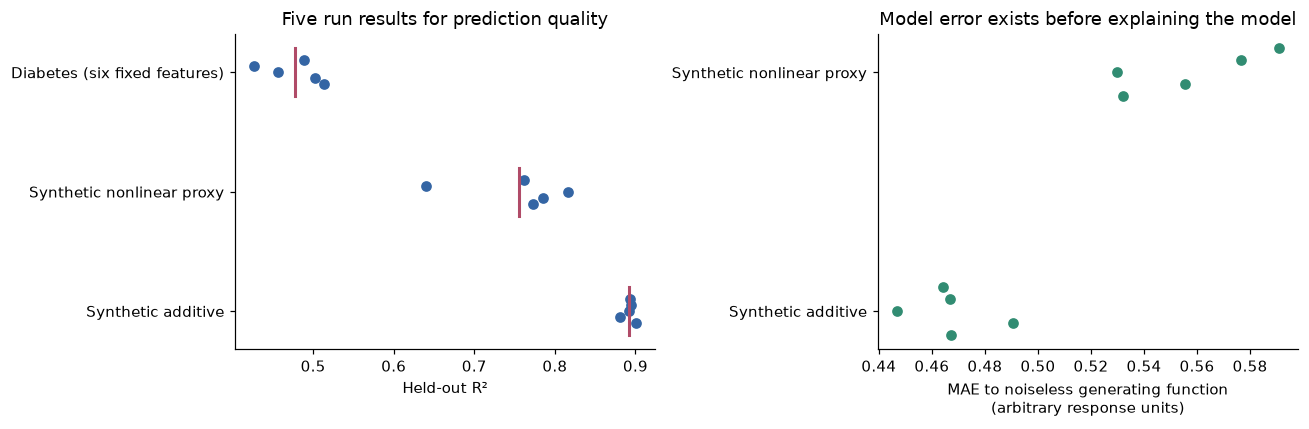

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, scenario in enumerate(SCENARIOS):
    selected = predictive[predictive.scenario == scenario]
    axes[0].scatter(selected.test_r2, np.full(len(selected),i)+np.linspace(-.1,.1,len(selected)), color='#3465a4')
    axes[0].plot([selected.test_r2.mean()]*2, [i-.2,i+.2], color='#b04b68', lw=2)
axes[0].set(yticks=range(len(SCENARIOS)), yticklabels=SCENARIOS, xlabel='Held-out R²', title='Five run results for prediction quality')
synthetic = predictive[predictive.scenario != SCENARIOS[-1]]
for i, scenario in enumerate(SCENARIOS[:2]):
    points = synthetic[synthetic.scenario==scenario].model_mae_to_noiseless_function
    axes[1].scatter(points, np.full(len(points),i)+np.linspace(-.1,.1,len(points)), color='#318c72')
axes[1].set(yticks=[0,1], yticklabels=SCENARIOS[:2], xlabel='MAE to noiseless generating function\n(arbitrary response units)',
            title='Model error exists before explaining the model')
plt.tight_layout()
fig.savefig(OUTPUT/'predictive_quality.png',bbox_inches='tight')
plt.show()

In [4]:
removal_rows = []
for run_id, run in runs.items():
    rng = np.random.default_rng(6000+run['seed'])
    donor_positions = rng.choice(len(run['training']),SETTINGS['empirical_donors'],replace=False)
    baselines = {'Training mean':run['training'].mean(axis=0,keepdims=True),
                 'Joint empirical donors':run['training'][donor_positions]}
    methods = [(name,0,run['results'][name]['values']) for name in ['SHAP Exact','LIME']]
    methods += [('Random ranking',i,rng.random(run['cases'].shape)) for i in range(SETTINGS['random_rankings'])]
    for manifest in manifests:
        if manifest['run_id']==run_id:
            manifest['removal_seed']=6000+run['seed']
            manifest['donor_training_positions']=donor_positions.tolist()
    for baseline, donors in baselines.items():
        for method, repeat, scores in methods:
            curve, area = removal_response(run['model'].predict,run['cases'],scores,donors)
            np.testing.assert_allclose(curve[:,0],0,atol=1e-10)
            for case in range(len(curve)):
                for k in range(curve.shape[1]):
                    removal_rows.append(dict(scenario=run['scenario'],seed=run['seed'],case=case,method=method,
                                             baseline=baseline,random_repeat=repeat,removed=k,
                                             absolute_output_change=float(curve[case,k]),
                                             removal_area=float(area[case]),
                                             scaled_area=float(area[case]/run['target_training_sd'])))
removal = pd.DataFrame(removal_rows)
# Average cases and random rankings first. A run, not a repeated query, is the summary unit.
run_areas = removal[removal.removed==0].groupby(['scenario','seed','baseline','method'],as_index=False)[['removal_area','scaled_area']].mean()
display(run_areas.groupby(['scenario','baseline','method'])[['removal_area','scaled_area']].agg(['mean','std']).round(3))

removal_area  \
                                                                            mean   
scenario                      baseline               method                        
Diabetes (six fixed features) Joint empirical donors LIME                 48.884   
                                                     Random ranking       33.609   
                                                     SHAP Exact           48.972   
                              Training mean          LIME                 37.549   
                                                     Random ranking       24.456   
                                                     SHAP Exact           37.670   
Synthetic additive            Joint empirical donors LIME                  2.386   
                                                     Random ranking        1.614   
                                                     SHAP Exact            2.390   
                              Training mean          LIME                  1.616   
                                                     Random ranking        1.142   
                                                     SHAP Exact            1.700   
Synthetic nonlinear proxy     Joint empirical donors LIME                  1.607   
                                                     Random ranking        1.043   
                                                     SHAP Exact            1.670   
                              Training mean          LIME                  1.219   
                                                     Random ranking        0.764   
                                                     SHAP Exact            1.267   

                                                                            \
                                                                       std   
scenario                      baseline               method                  
Diabetes (six fixed features) Joint empirical donors LIME            6.783   
                                                     Random ranking  6.506   
                                                     SHAP Exact      7.275   
                              Training mean          LIME            7.803   
                                                     Random ranking  7.118   
                                                     SHAP Exact      8.703   
Synthetic additive            Joint empirical donors LIME            0.627   
                                                     Random ranking  0.317   
                                                     SHAP Exact      0.609   
                              Training mean          LIME            0.490   
                                                     Random ranking  0.271   
                                                     SHAP Exact      0.504   
Synthetic nonlinear proxy     Joint empirical donors LIME            0.291   
                                                     Random ranking  0.190   
                                                     SHAP Exact      0.400   
                              Training mean          LIME            0.496   
                                                     Random ranking  0.270   
                                                     SHAP Exact      0.589   

                                                                    scaled_area  \
                                                                           mean   
scenario                      baseline               method                       
Diabetes (six fixed features) Joint empirical donors LIME                 0.639   
                                                     Random ranking       0.439   
                                                     SHAP Exact           0.640   
                              Training mean          LIME                 0.491   
                                                     Random ranking       0.319   


## 5. Paired comparisons and replacement sensitivity

The plot divides removal area by the **training-target SD** to display readable dimensionless values, while the CSV retains target-unit results. This rescaling does not make different problems equivalent. Each dot averages eight cases within one run (and, for the random control, five rankings). Methods are paired through their common run, cases and replacements.

Use the paired difference table to see how much a method exceeds the random control **within each run**. We report its mean and SD across five repeats, not a hypothesis-test result. The two replacement strategies may support different conclusions. We do not select the more favorable one after seeing results.

method                                               SHAP Exact minus random  \
                                                                        mean   
scenario                      baseline                                         
Diabetes (six fixed features) Joint empirical donors                   0.201   
                              Training mean                            0.174   
Synthetic additive            Joint empirical donors                   0.293   
                              Training mean                            0.211   
Synthetic nonlinear proxy     Joint empirical donors                   0.289   
                              Training mean                            0.231   

method                                                      LIME minus random  \
                                                        std              mean   
scenario                      baseline                                          
Diabetes (six fixed features) Joint empirical donors  0.062             0.200   
                              Training mean           0.081             0.172   
Synthetic additive            Joint empirical donors  0.132             0.292   
                              Training mean           0.124             0.179   
Synthetic nonlinear proxy     Joint empirical donors  0.093             0.261   
                              Training mean           0.148             0.209   

method                                                       \
                                                        std   
scenario                      baseline                        
Diabetes (six fixed features) Joint empirical donors  0.060   
                              Training mean           0.078   
Synthetic additive            Joint empirical donors  0.137   
                              Training mean           0.113   
Synthetic nonlinear proxy     Joint empirical donors  0.047   
                              Training mean           0.104   

method                                               SHAP Exact minus LIME  \
                                                                      mean   
scenario                      baseline                                       
Diabetes (six fixed features) Joint empirical donors                 0.001   
                              Training mean                          0.002   
Synthetic additive            Joint empirical donors                 0.001   
                              Training mean                          0.032   
Synthetic nonlinear proxy     Joint empirical donors                 0.029   
                              Training mean                          0.022   

method                                                       
                                                        std  
scenario                      baseline                       
Diabetes (six fixed features) Joint empirical donors  0.008  
                              Training mean           0.018  
Synthetic additive            Joint empirical donors  0.015  
                              Training mean           0.022  
Synthetic nonlinear proxy     Joint empirical donors  0.050  
                              Training mean           0.044

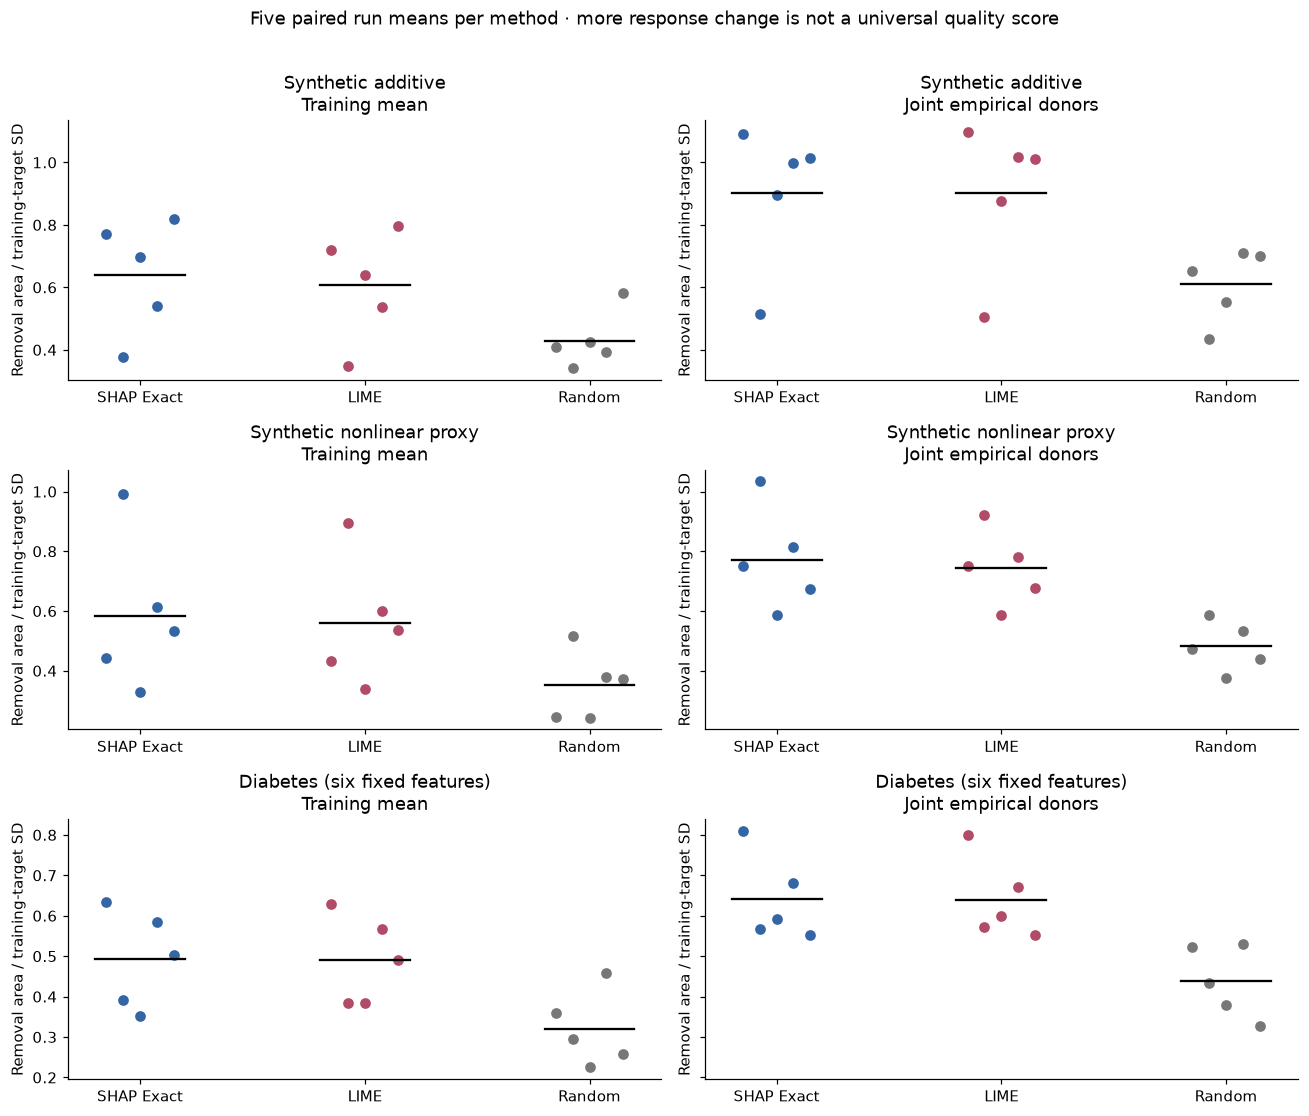

In [5]:
paired = run_areas.pivot(index=['scenario','seed','baseline'],columns='method',values='scaled_area').reset_index()
paired['SHAP Exact minus random'] = paired['SHAP Exact']-paired['Random ranking']
paired['LIME minus random'] = paired['LIME']-paired['Random ranking']
paired['SHAP Exact minus LIME'] = paired['SHAP Exact']-paired['LIME']
display(paired.groupby(['scenario','baseline'])[['SHAP Exact minus random','LIME minus random','SHAP Exact minus LIME']].agg(['mean','std']).round(3))
fig, axes = plt.subplots(3,2,figsize=(12,10),sharey='row')
for row, scenario in enumerate(SCENARIOS):
    for col, baseline in enumerate(['Training mean','Joint empirical donors']):
        ax=axes[row,col]
        data=run_areas[(run_areas.scenario==scenario)&(run_areas.baseline==baseline)]
        for i, method in enumerate(['SHAP Exact','LIME','Random ranking']):
            values=data[data.method==method].scaled_area.to_numpy()
            ax.scatter(i+np.linspace(-.15,.15,len(values)),values,color=COLORS[method])
            ax.plot([i-.2,i+.2],[values.mean()]*2,color='black',lw=1.5)
        ax.set(xticks=[0,1,2],xticklabels=['SHAP Exact','LIME','Random'],title=f'{scenario}\n{baseline}',
               ylabel='Removal area / training-target SD')
fig.suptitle('Five paired run means per method · more response change is not a universal quality score',y=1.01)
plt.tight_layout()
fig.savefig(OUTPUT/'paired_removal.png',bbox_inches='tight')
plt.show()

## 6. Explaining the learned model is different from recovering the generating function

Apply the **same finite-background game** to the known noiseless synthetic function and to the fitted forest. Their attributions can differ because the forest approximates the function imperfectly, uses correlated proxies, and can learn sampling artifacts. SHAP Exact matching exact forest Shapley values does not imply it matches the data-generating function.

The following plot uses the nonlinear proxy scenario. The generating function never consumes $x_1$, so its marginal-game attribution to $x_1$ is zero. The forest may use that proxy. This is a statement about our synthetic construction; observational real data alone do not identify such a causal or functional ground truth. Mean absolute contributions also hide sign changes across cases.

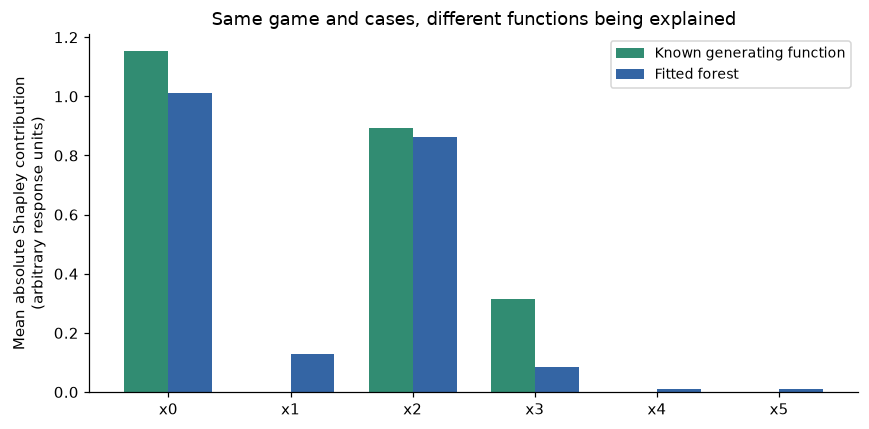

In [6]:
proxy = attributions[attributions.scenario=='Synthetic nonlinear proxy']
np.testing.assert_allclose(proxy.loc[proxy.feature=='x1','generating_function_shap'],0,atol=1e-10)
function_comparison = proxy.groupby('feature')[['fitted_model_shap','generating_function_shap']].agg(lambda values:np.abs(values).mean())
fig,ax=plt.subplots(figsize=(8,4))
positions=np.arange(len(function_comparison))
ax.bar(positions-.18,function_comparison.generating_function_shap,width=.36,label='Known generating function',color='#318c72')
ax.bar(positions+.18,function_comparison.fitted_model_shap,width=.36,label='Fitted forest',color='#3465a4')
ax.set(xticks=positions,xticklabels=function_comparison.index,ylabel='Mean absolute Shapley contribution\n(arbitrary response units)',
       title='Same game and cases, different functions being explained')
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(OUTPUT/'function_vs_model.png',bbox_inches='tight')
plt.show()

## 7. Resource measurements

These values use the measurement boundaries defined above. SHAP Exact and the simple reference use different batching and bookkeeping. Identical explanatory games do not imply identical observed prediction-call budgets; the table records the actual calls, including returned diagnostics. Both use the same fitted prediction interface and explanatory game. Peak traced allocations cover a separate rerun and cannot substitute for native-process memory profiling or a deployment memory limit. The exact reference trades exponential work for a known numerical answer and is feasible here only because there are six features.

seconds           \
                                                          mean      min   
scenario                      method                                      
Diabetes (six fixed features) Exact Shapley reference  0.01194  0.00958   
                              LIME                     0.11332  0.10865   
                              SHAP Exact               0.03297  0.03233   
Synthetic additive            Exact Shapley reference  0.00819  0.00769   
                              LIME                     0.11242  0.10877   
                              SHAP Exact               0.42496  0.02784   
Synthetic nonlinear proxy     Exact Shapley reference  0.00765  0.00736   
                              LIME                     0.11837  0.10543   
                              SHAP Exact               0.02828  0.02688   

                                                                \
                                                           max   
scenario                      method                             
Diabetes (six fixed features) Exact Shapley reference  0.02018   
                              LIME                     0.11694   
                              SHAP Exact               0.03359   
Synthetic additive            Exact Shapley reference  0.00917   
                              LIME                     0.11919   
                              SHAP Exact               2.00730   
Synthetic nonlinear proxy     Exact Shapley reference  0.00822   
                              LIME                     0.14062   
                              SHAP Exact               0.02935   

                                                      seconds_per_case  \
                                                                  mean   
scenario                      method                                     
Diabetes (six fixed features) Exact Shapley reference          0.00149   
                              LIME                             0.01417   
                              SHAP Exact                       0.00412   
Synthetic additive            Exact Shapley reference          0.00102   
                              LIME                             0.01405   
                              SHAP Exact                       0.05312   
Synthetic nonlinear proxy     Exact Shapley reference          0.00096   
                              LIME                             0.01480   
                              SHAP Exact                       0.00354   

                                                                         \
                                                           min      max   
scenario                      method                                      
Diabetes (six fixed features) Exact Shapley reference  0.00120  0.00252   
                              LIME                     0.01358  0.01462   
                              SHAP Exact               0.00404  0.00420   
Synthetic additive            Exact Shapley reference  0.00096  0.00115   
                              LIME                     0.01360  0.01490   
                              SHAP Exact               0.00348  0.25091   
Synthetic nonlinear proxy     Exact Shapley reference  0.00092  0.00103   
                              LIME                     0.01318  0.01758   
                              SHAP Exact               0.00336  0.00367   

                                                      predict_api_calls      \
                                                                   mean min   
scenario                      method                                          
Diabetes (six fixed features) Exact Shapley reference               1.0   1   
                              LIME                                  9.0   9   
                              SHAP Exact                           16.0  16   
Synthetic additive            Exact Shapley reference               1.0   1   
                  

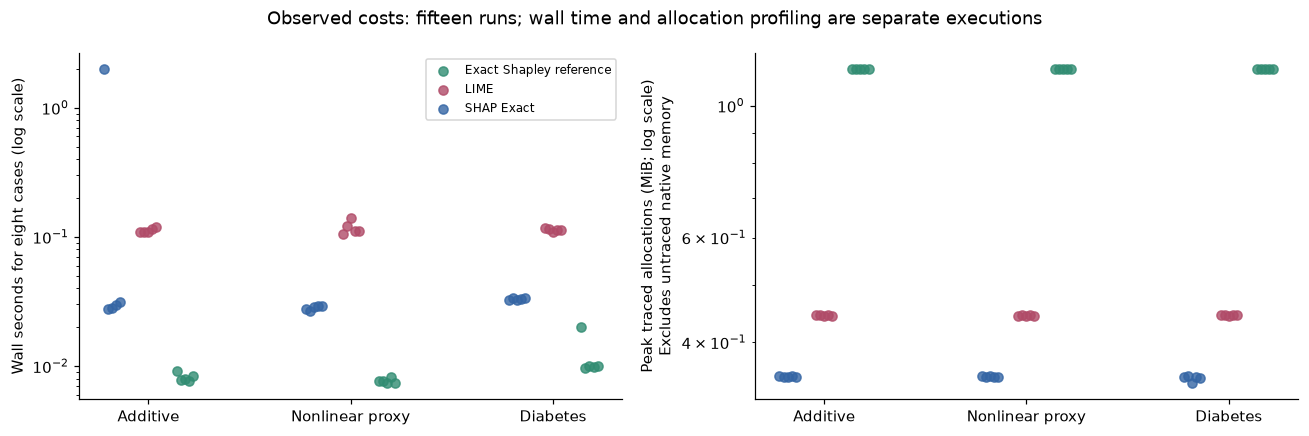

In [7]:
resource_summary=resources.groupby(['scenario','method'])[['seconds','seconds_per_case','predict_api_calls','predict_api_rows','peak_traced_bytes']].agg(['mean','min','max'])
display(resource_summary.round(5))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for method,group in resources.groupby('method'):
    for ax,metric,label in [(axes[0],'seconds','Wall seconds for eight cases (log scale)'),
                            (axes[1],'peak_traced_bytes','Peak traced allocations (MiB; log scale)\nExcludes untraced native memory')]:
        for i,scenario in enumerate(SCENARIOS):
            data=group[group.scenario==scenario]
            offset={'SHAP Exact':-.18,'LIME':0,'Exact Shapley reference':.18}[method]
            values=data[metric].to_numpy()/(1024**2 if metric=='peak_traced_bytes' else 1)
            ax.scatter(np.full(len(values),i)+offset+np.linspace(-.04,.04,len(values)),values,
                       color=COLORS[method],alpha=.8,label=method if i==0 else None)
        ax.set(xticks=range(3),xticklabels=['Additive','Nonlinear proxy','Diabetes'],ylabel=label,yscale='log')
axes[0].legend(fontsize=8)
fig.suptitle('Observed costs: fifteen runs; wall time and allocation profiling are separate executions')
plt.tight_layout()
fig.savefig(OUTPUT/'resources.png',bbox_inches='tight')
plt.show()

## 8. Save records and state what remains unresolved

The machine-readable record includes every case's observations, attributions, explanation diagnostics and removal curves; measured resources; dataset fingerprints; split/case/background indices; seeds; model parameters; and package/machine details. Random rankings and donor draws are recoverable from their recorded seeds. Source hashes identify the executed notebook and metric code, even when work has not yet been committed.

This protocol does not establish causality, compare conditional-background methods, measure total native memory, prove a ranking across datasets, or evaluate usefulness to people. Broader studies need prespecified datasets/tasks, model-selection rules, domain-valid replacements, independent replication and human task outcomes. Plotting a mean without the underlying repeats would obscure important variation.

In [8]:
tables=dict(predictive_quality=predictive,resources=resources,case_diagnostics=diagnostics,attributions=attributions,
             removal=removal,run_areas=run_areas,paired_differences=paired)
for name,table in tables.items():
    table.to_csv(OUTPUT/f'{name}.csv',index=False)
try:
    commit=subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip()
    git_dirty=bool(subprocess.check_output(['git','status','--porcelain'],cwd=ROOT,text=True).strip())
except (OSError,subprocess.CalledProcessError):
    commit=None
    git_dirty=None  # Repository state is unknown outside a Git checkout.
report=dict(schema_version=1,study='Regression explanation benchmark',git_commit=commit,git_dirty=git_dirty,
             source_sha256={name:hashlib.sha256(Path(name).read_bytes()).hexdigest() for name in ['Regression_Benchmark.ipynb','regression_helpers.py']},
             settings=SETTINGS,seeds=SEEDS,scenarios=SCENARIOS,manifests=manifests,
             generating_functions={'Synthetic additive':'2*x0 - 1.5*x1 + 0.75*x2',
                                   'Synthetic nonlinear proxy':'2*sin(x0) + x2**2 - 1 + 0.8*x2*x3'},
             synthetic_noise_sd=.6,synthetic_proxy_correlation=.97,
             resource_definitions={'seconds':'wall time for construction/explanation/returned diagnostics; excludes fitting and tracemalloc',
                                   'predict_api_calls':'observed public model.predict invocations during the operation; not arithmetic operations',
                                   'predict_api_rows':'rows passed to observed model.predict calls',
                                   'peak_traced_bytes':'peak tracemalloc allocations in a separate rerun; excludes already-fitted model and untraced native memory'},
             variability='Five run means; synthetic datasets are regenerated; diabetes splits overlap; SD is not a confidence interval.',
             environment={'python':sys.version,'platform':platform.platform(),'machine':platform.machine(),
                          'packages':{name:importlib.metadata.version(name) for name in ['numpy','pandas','scikit-learn','shap','lime','matplotlib']}},
             tables={name:json.loads(table.to_json(orient='records', double_precision=15)) for name,table in tables.items()})
(OUTPUT/'results.json').write_text(json.dumps(report,indent=2,allow_nan=False)+'\n')
print(f'Saved raw records, reproducibility metadata and figures to {OUTPUT}')

Saved raw records, reproducibility metadata and figures to /Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/validation/regression-benchmark


## Primary references and implementation details

- [Lundberg & Lee — A Unified Approach to Interpreting Model Predictions](https://arxiv.org/abs/1705.07874), and [ExactExplainer documentation](https://shap.readthedocs.io/en/latest/generated/shap.ExactExplainer.html): attribution game and exact model-agnostic implementation.
- [Ribeiro et al. — “Why Should I Trust You?”](https://arxiv.org/abs/1602.04938): local surrogate explanations; neighborhood fit is not global model fidelity.
- [Hooker et al. — A Benchmark for Interpretability Methods in Deep Neural Networks](https://arxiv.org/abs/1806.10758): feature removal and distribution-shift limitations. Our regression removal experiment does not implement their retraining benchmark.
- [Hedström et al. — Quantus](https://jmlr.org/papers/v24/22-0142.html): evaluate explanation methods with several criteria and sensitivity to evaluation choices.
- [scikit-learn diabetes dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html) for the bundled real-data task.
- [Python `tracemalloc`](https://docs.python.org/3/library/tracemalloc.html) for the precise allocation measurement interface; use appropriate process/native profilers when total memory is the requirement.